# Recommendation

<img src="https://www.pacificdataintegrators.com/hubfs/a-vibrant-retail-themed-illustration-with-a-deep-p-bal2vIl_StOKg4qpYTv6Wg-IcXSR6N_SxaaOyvOi4pBRg.jpeg" width=900>

### Dataset Download  
You can download the CSV file here:  
[https://amanxai.com/2021/03/23/amazon-recommendation-system-using-python/)

### Introduction
Recommender systems are widely used in e-commerce platforms to help users discover relevant products and improve the overall user experience.
In this project, an item-based recommendation system was developed using the Amazon Electronics ratings dataset.
Due to the large scale and high sparsity of the data, a sparse user–item matrix was constructed to efficiently model user–product interactions.
Cosine similarity was applied to identify similar products based on shared user ratings and generate personalized recommendations.

### Import Libraries

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from scipy import spatial
from sklearn.preprocessing import normalize
import joblib
import warnings
warnings.filterwarnings('ignore')

### Read Data

In [2]:
df=pd.read_csv('ratings_Electronics (1).csv')

### EDA

In [3]:
df.head()

,AKM1MP6P0OYPR,0132793040,5.0,1365811200
0,A2CX7LUOHB2NDG,0321732944,5.0,1341100800
1,A2NWSAGRHCP8N5,0439886341,1.0,1367193600
2,A2WNBOD3WNDNKT,0439886341,3.0,1374451200
3,A1GI0U4ZRJA8WN,0439886341,1.0,1334707200
4,A1QGNMC6O1VW39,0511189877,5.0,1397433600


In [4]:
df.tail()

,AKM1MP6P0OYPR,0132793040,5.0,1365811200
7824476,A2YZI3C9MOHC0L,BT008UKTMW,5.0,1396569600
7824477,A322MDK0M89RHN,BT008UKTMW,5.0,1313366400
7824478,A1MH90R0ADMIK0,BT008UKTMW,4.0,1404172800
7824479,A10M2KEFPEQDHN,BT008UKTMW,4.0,1297555200
7824480,A2G81TMIOIDEQQ,BT008V9J9U,5.0,1312675200


In [5]:
df.shape

(7824481, 4)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7824481 entries, 0 to 7824480
Data columns (total 4 columns):
 #   Column         Dtype  
---  ------         -----  
 0   AKM1MP6P0OYPR  object 
 1   0132793040     object 
 2   5.0            float64
 3   1365811200     int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 238.8+ MB


In [7]:
df.isnull().sum()

AKM1MP6P0OYPR    0
0132793040       0
5.0              0
1365811200       0
dtype: int64

In [8]:
df.columns=['user_id','product_id','rating','timestamp']

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7824481 entries, 0 to 7824480
Data columns (total 4 columns):
 #   Column      Dtype  
---  ------      -----  
 0   user_id     object 
 1   product_id  object 
 2   rating      float64
 3   timestamp   int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 238.8+ MB


In [10]:
df['rating'].value_counts().sort_index()

rating
1.0     901765
2.0     456322
3.0     633073
4.0    1485781
5.0    4347540
Name: count, dtype: int64

In [11]:
df['user_id'].nunique(), df['product_id'].nunique()

(4201696, 476001)

In [12]:
df.groupby('product_id')['rating'].count().describe()

count    476001.000000
mean         16.437951
std         112.702749
min           1.000000
25%           1.000000
50%           2.000000
75%           7.000000
max       18244.000000
Name: rating, dtype: float64

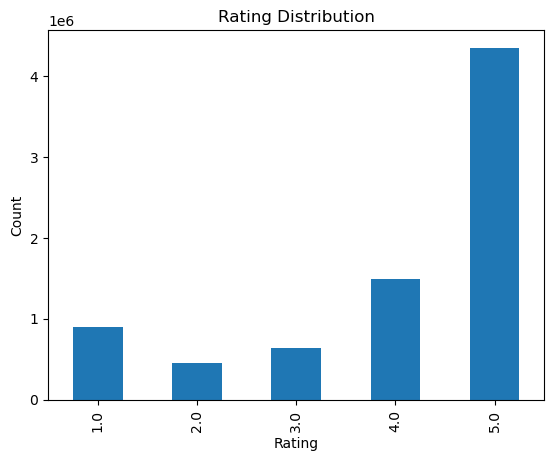

In [13]:
df["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

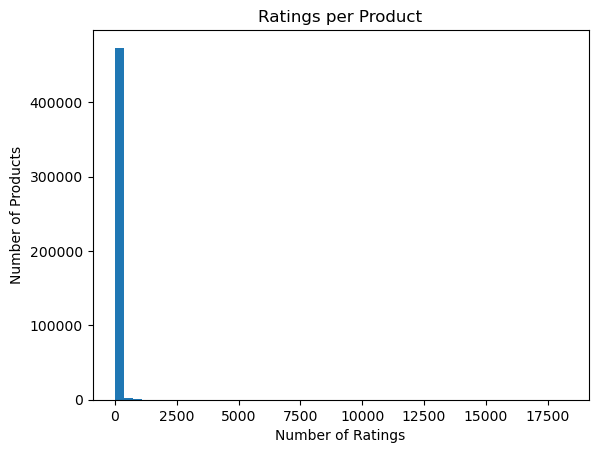

In [14]:
product=df.groupby("product_id").size()

plt.hist(product, bins=50)
plt.title("Ratings per Product")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Products")
plt.show()

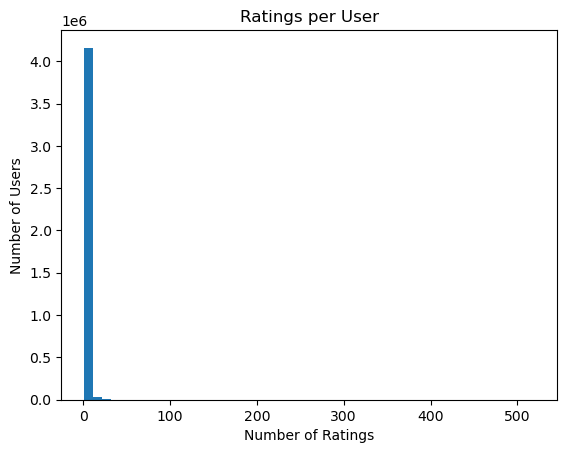

In [15]:
user=df.groupby("user_id").size()

plt.hist(user, bins=50)
plt.title("Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.show()

In [16]:
top_item=4000
top_user=200000

top_items=(df.groupby("product_id").size()
             .sort_values(ascending=False).head(top_item).index)

df_items=df[df["product_id"].isin(top_items)].copy()

top_users=(df_items.groupby("user_id").size()
             .sort_values(ascending=False).head(top_user).index)

df=df_items[df_items["user_id"].isin(top_users)].copy()

In [17]:
print("Rows:", df.shape)
print("Unique users:", df["user_id"].nunique())
print("Unique items:", df["product_id"].nunique())
print(df.groupby("product_id").size().describe())

Rows: (858212, 4)
Unique users: 200000
Unique items: 4000
count    4000.000000
mean      214.553000
std       300.158154
min        13.000000
25%        89.000000
50%       135.000000
75%       222.000000
max      5610.000000
dtype: float64


In [18]:
user_cat=pd.Categorical(df["user_id"])
item_cat=pd.Categorical(df["product_id"])
R=csr_matrix((df["rating"].astype(np.float32).values,(user_cat.codes, item_cat.codes)),shape=(len(user_cat.categories), len(item_cat.categories)))

product_ids=item_cat.categories
prod_to_idx={pid: i for i, pid in enumerate(product_ids)}

In [19]:
print("Sparse matrix shape:", R.shape)
print("Non-zeros:", R.nnz)

Sparse matrix shape: (200000, 4000)
Non-zeros: 858212


In [20]:
num_users = R.shape[0]
num_items = R.shape[1]
num_interactions = R.nnz

sparsity = 1 - (num_interactions / (num_users * num_items))

print(f"Sparsity of the user-item matrix: {sparsity:.4f}")

Sparsity of the user-item matrix: 0.9989


In [21]:
def recommend(product_id, top_n=10, min_sim=0.01):
    if product_id not in prod_to_idx:
        return pd.DataFrame({"message": ["Product not found."]})

    j=prod_to_idx[product_id]
    item_vec=R[:, j].T

    sims=cosine_similarity(item_vec, R.T).ravel()
    sims[j]=-1.0

    valid=np.where(sims >= min_sim)[0]
    top_idx=valid[np.argsort(sims[valid])[::-1][:top_n]]

    return pd.DataFrame({
        "recommended_product_id": product_ids[top_idx],
        "similarity": sims[top_idx].astype(float)
    })

In [22]:
test_pid=product_ids[0]
recommend(test_pid, top_n=10, min_sim=0.01)

,recommended_product_id,similarity
0,B000WYVBR0,0.023252
1,B0038KR8WM,0.021944
2,B003ES5ZUU,0.019811
3,B002BZFSYA,0.018440
4,B001GTT0VO,0.018127
5,B005D91G38,0.017495
6,B004GGNBJ6,0.015961
7,B000RT8CM2,0.015918
8,B009BVDV5A,0.015791
9,B004FJV8EE,0.014987


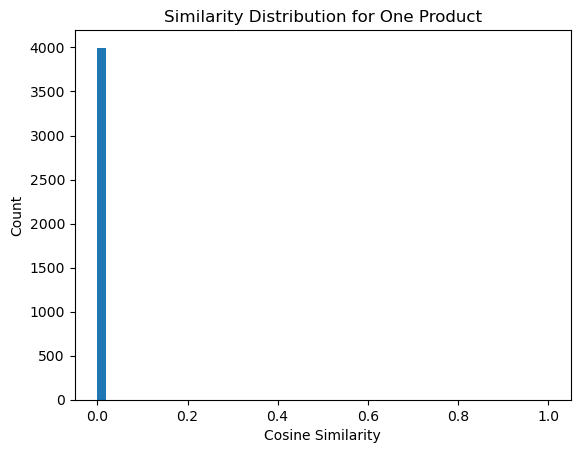

In [23]:
test_pid=product_ids[0]
j=prod_to_idx[test_pid]

item_vec=R[:, j].T
sims=cosine_similarity(item_vec, R.T).ravel()

plt.hist(sims, bins=50)
plt.title("Similarity Distribution for One Product")
plt.xlabel("Cosine Similarity")
plt.ylabel("Count")
plt.show()

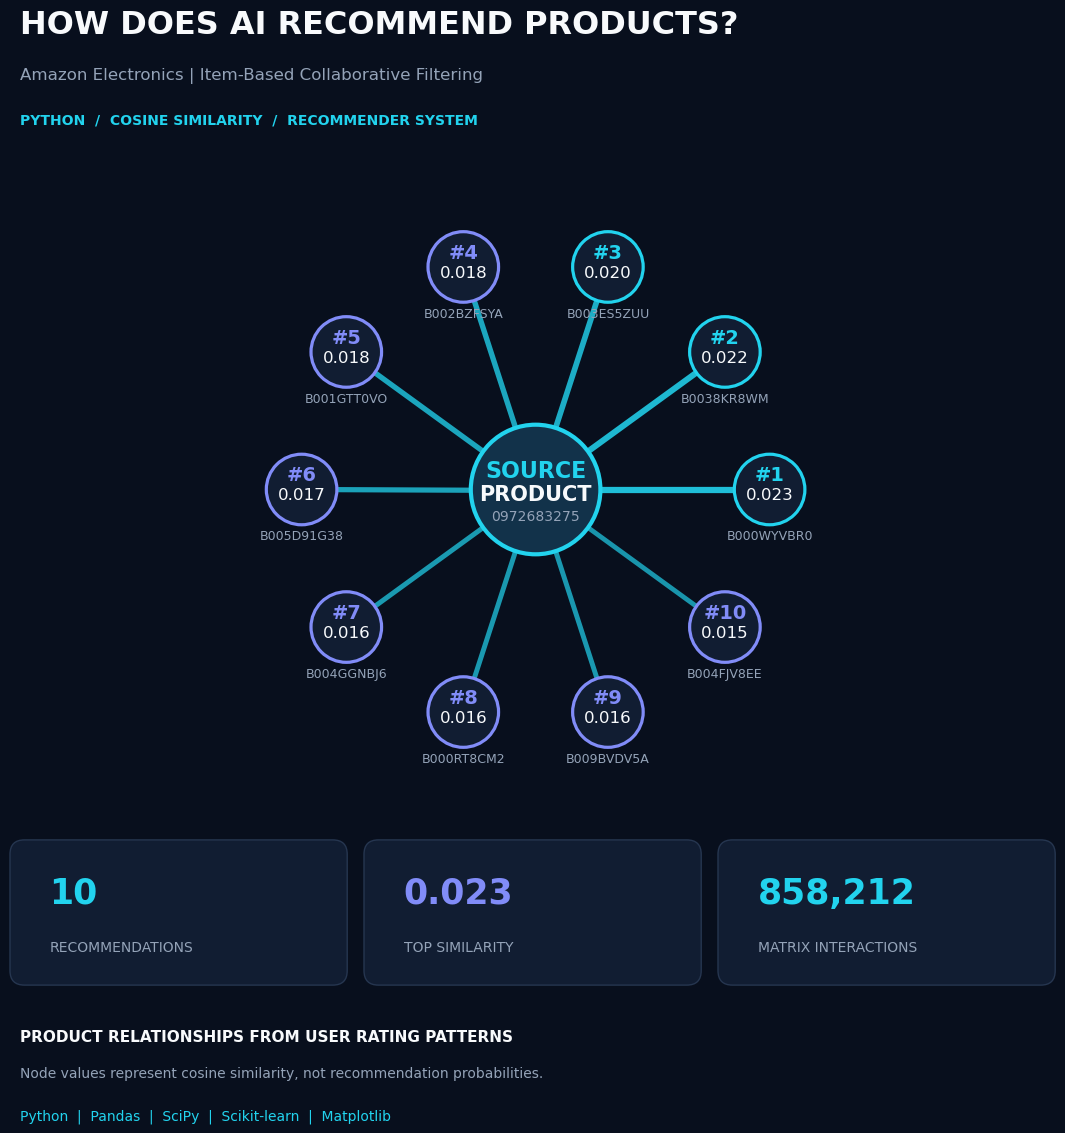

In [24]:
# Real recommendations
product_id = product_ids[0]
recs = recommend(product_id, top_n=10, min_sim=0.01)

if 'similarity' not in recs.columns or recs.empty:
    raise ValueError('No recommendations found.')

names = recs['recommended_product_id'].astype(str).tolist()
scores = recs['similarity'].to_numpy(dtype=float)
n = len(scores)

# Colors
bg = '#080F1D'
panel = '#111D32'
cyan = '#22D3EE'
purple = '#818CF8'
white = '#F8FAFC'
muted = '#94A3B8'

fig = plt.figure(figsize=(12, 12), facecolor=bg)

# Header
fig.text(0.07, 0.94, 'HOW DOES AI RECOMMEND PRODUCTS?',
         color=white, fontsize=23, fontweight='bold')

fig.text(0.07, 0.902,
         'Amazon Electronics | Item-Based Collaborative Filtering',
         color=muted, fontsize=12)

fig.text(0.07, 0.865,
         'PYTHON  /  COSINE SIMILARITY  /  RECOMMENDER SYSTEM',
         color=cyan, fontsize=10, fontweight='bold')

# Network
ax = fig.add_axes([0.08, 0.29, 0.84, 0.54])
ax.set_facecolor(bg)
ax.set_aspect('equal')
ax.axis('off')

angles = np.linspace(0, 2 * np.pi, n, endpoint=False)
radius = 3.25

positions = [
    (radius * np.cos(a), radius * np.sin(a))
    for a in angles
]

max_score = max(scores.max(), 1e-12)

# Connections
for (x, y), score in zip(positions, scores):
    strength = max(score / max_score, 0)

    ax.plot(
        [0, x], [0, y],
        color=cyan,
        linewidth=1.5 + 3 * strength,
        alpha=0.3 + 0.6 * strength,
        zorder=1
    )

# Recommended product nodes
for i, ((x, y), name, score) in enumerate(
    zip(positions, names, scores)
):
    color = cyan if i < 3 else purple

    ax.add_patch(Circle(
        (x, y), 0.49,
        facecolor=panel,
        edgecolor=color,
        linewidth=2.3,
        zorder=3
    ))

    ax.text(x, y + 0.12, f'#{i + 1}',
            color=color, fontsize=14,
            ha='center', fontweight='bold', zorder=4)

    ax.text(x, y - 0.14, f'{score:.3f}',
            color=white, fontsize=12,
            ha='center', zorder=4)

    ax.text(x, y - 0.70, name,
            color=muted, fontsize=9,
            ha='center')

# Source product
ax.add_patch(Circle(
    (0, 0), 0.9,
    facecolor='#12324A',
    edgecolor=cyan,
    linewidth=3,
    zorder=5
))

ax.text(0, 0.17, 'SOURCE',
        color=cyan, fontsize=16,
        fontweight='bold', ha='center', zorder=6)

ax.text(0, -0.15, 'PRODUCT',
        color=white, fontsize=15,
        fontweight='bold', ha='center', zorder=6)

ax.text(0, -0.43, str(product_id),
        color=muted, fontsize=10,
        ha='center', zorder=6)

ax.set_xlim(-4.8, 4.8)
ax.set_ylim(-4.5, 4.5)

# KPI cards
def kpi_card(x, value, label, color):
    fig.add_artist(FancyBboxPatch(
        (x, 0.155), 0.265, 0.105,
        transform=fig.transFigure,
        boxstyle='round,pad=0.008,rounding_size=0.012',
        facecolor=panel,
        edgecolor='#263650',
        linewidth=1
    ))

    fig.text(x + 0.025, 0.215, value,
             color=color, fontsize=25, fontweight='bold')

    fig.text(x + 0.025, 0.175, label,
             color=muted, fontsize=10)

kpi_card(0.07, str(n), 'RECOMMENDATIONS', cyan)
kpi_card(0.365, f'{scores.max():.3f}', 'TOP SIMILARITY', purple)
kpi_card(0.66, f'{R.nnz:,}', 'MATRIX INTERACTIONS', cyan)

# Footer
fig.text(0.07, 0.10,
         'PRODUCT RELATIONSHIPS FROM USER RATING PATTERNS',
         color=white, fontsize=11, fontweight='bold')

fig.text(0.07, 0.07,
         'Node values represent cosine similarity, not recommendation probabilities.',
         color=muted, fontsize=10)

fig.text(0.07, 0.035,
         'Python  |  Pandas  |  SciPy  |  Scikit-learn  |  Matplotlib',
         color=cyan, fontsize=10)

# Export
plt.savefig(
    'amazon_recommendation_network.png',
    dpi=300,
    facecolor=bg,
    bbox_inches='tight',
    pad_inches=0.2
)

plt.show()

### Data Quality & Sparsity Analysis

Analyzing user activity, product popularity, and matrix sparsity
to understand the limitations of collaborative filtering.

In [25]:
user_counts = np.diff(R.tocsr().indptr)
product_counts = np.diff(R.tocsc().indptr)

n_users, n_products = R.shape
n_interactions = R.nnz
density = n_interactions / (n_users * n_products)

stats = {
    'Users': n_users,
    'Products': n_products,
    'Interactions': n_interactions,
    'Sparsity (%)': round((1 - density) * 100, 4),
    'Avg ratings per user': round(user_counts.mean(), 2),
    'Avg ratings per product': round(product_counts.mean(), 2),
    'Users with 1 rating (%)': round(
        np.mean(user_counts == 1) * 100, 2
    ),
    'Users with 2+ ratings (%)': round(
        np.mean(user_counts >= 2) * 100, 2
    ),
    'Products with 5+ ratings (%)': round(
        np.mean(product_counts >= 5) * 100, 2
    )
}

display(pd.DataFrame(
    stats.items(),
    columns=['Metric', 'Value']
))

,Metric,Value
0,Users,200000.0000
1,Products,4000.0000
2,Interactions,858212.0000
3,Sparsity (%),99.8927
4,Avg ratings per user,4.2900
5,Avg ratings per product,214.5500
6,Users with 1 rating (%),0.0000
7,Users with 2+ ratings (%),100.0000
8,Products with 5+ ratings (%),100.0000


In [26]:
# Source product
test_pid = product_ids[0]
j = prod_to_idx[test_pid]

# Binary user-product interactions
R_binary = R.tocsr().copy()
R_binary.data = np.ones_like(R_binary.data)

# Users who rated the source product
source_users = R_binary[:, j]

# Number of shared users for each product
shared_users = (
    source_users.T @ R_binary
).toarray().ravel()

# Number of ratings per product
product_counts = np.diff(R_binary.tocsc().indptr)

# Top recommendations
recs = recommend(test_pid, top_n=10, min_sim=0.01).copy()

recs['shared_users'] = [
    int(shared_users[prod_to_idx[pid]])
    for pid in recs['recommended_product_id']
]

recs['product_ratings'] = [
    int(product_counts[prod_to_idx[pid]])
    for pid in recs['recommended_product_id']
]

print('Source product:', test_pid)
print('Source product ratings:', product_counts[j])

display(recs[
    ['recommended_product_id', 'similarity',
     'shared_users', 'product_ratings']
])

Source product: 0972683275
Source product ratings: 279


,recommended_product_id,similarity,shared_users,product_ratings
0,B000WYVBR0,0.023252,11,920
1,B0038KR8WM,0.021944,4,122
2,B003ES5ZUU,0.019811,22,4988
3,B002BZFSYA,0.018440,3,72
4,B001GTT0VO,0.018127,9,754
5,B005D91G38,0.017495,2,71
6,B004GGNBJ6,0.015961,3,115
7,B000RT8CM2,0.015918,3,170
8,B009BVDV5A,0.015791,2,70
9,B004FJV8EE,0.014987,3,101


In [27]:
# Compare recommendations by shared-user threshold
thresholds = [2, 3, 5, 10, 20]

results = []

for threshold in thresholds:
    filtered = recs[recs['shared_users'] >= threshold]

    results.append({
        'Min shared users': threshold,
        'Recommendations': len(filtered),
        'Avg similarity': (
            filtered['similarity'].mean()
            if len(filtered) else np.nan
        ),
        'Max similarity': (
            filtered['similarity'].max()
            if len(filtered) else np.nan
        )
    })

comparison = pd.DataFrame(results)
display(comparison)

,Min shared users,Recommendations,Avg similarity,Max similarity
0,2,10,0.018172,0.023252
1,3,8,0.018555,0.023252
2,5,3,0.020397,0.023252
3,10,2,0.021531,0.023252
4,20,1,0.019811,0.019811


In [28]:
def recommend_improved(product_id, top_n=10, min_shared=5):
    j = prod_to_idx[product_id]

    # Similarity across all products
    sims = cosine_similarity(R[:, j].T, R.T).ravel()

    # Shared users across all products
    binary = R.tocsr().copy()
    binary.data = np.ones_like(binary.data)

    shared = (binary[:, j].T @ binary).toarray().ravel()

    # Candidate table
    results = pd.DataFrame({
        'product_id': product_ids,
        'similarity': sims,
        'shared_users': shared
    })

    # Filter and rank
    results = results[
        (results['product_id'] != product_id) &
        (results['shared_users'] >= min_shared)
    ]

    return results.sort_values(
        'similarity', ascending=False
    ).head(top_n).reset_index(drop=True)


# Test improved recommendations
improved_recs = recommend_improved(
    test_pid,
    top_n=10,
    min_shared=5
)

display(improved_recs)

,product_id,similarity,shared_users
0,B000WYVBR0,0.023252,11.0
1,B003ES5ZUU,0.019811,22.0
2,B001GTT0VO,0.018127,9.0
3,B000ID7QNI,0.013901,5.0
4,B0088PUEPK,0.010077,5.0
5,B004XC6GJ0,0.009749,6.0
6,B0019EHU8G,0.009060,10.0
7,B0012S4APK,0.008077,5.0
8,B005FYNSPK,0.008035,6.0
9,B0002L5R78,0.007416,7.0


In [29]:
user_counts = np.diff(R.tocsr().indptr)

print('Users with 5+ ratings:', np.sum(user_counts >= 5))
print('Users with 10+ ratings:', np.sum(user_counts >= 10))
print('Users with 20+ ratings:', np.sum(user_counts >= 20))

Users with 5+ ratings: 52740
Users with 10+ ratings: 8158
Users with 20+ ratings: 1129


### Offline Evaluation — Leave-One-Out Split

Holding out one positive interaction per eligible user
to evaluate recommendation quality without data leakage.

In [30]:
rng = np.random.default_rng(42)

# Work with a copy of the original matrix
R_full = R.tocsr()
R_train = R_full.tolil(copy=True)

# Users with at least 5 interactions
user_counts = np.diff(R_full.indptr)
eligible_users = np.where(user_counts >= 5)[0]

test_users = []
test_items = []

for user in eligible_users:
    start, end = R_full.indptr[user:user + 2]
    items = R_full.indices[start:end]
    ratings = R_full.data[start:end]

    # Positive interactions only
    positive_items = items[ratings >= 4]

    if len(positive_items) == 0:
        continue

    held_out = rng.choice(positive_items)

    test_users.append(user)
    test_items.append(held_out)

    # Remove held-out interaction from training
    R_train[user, held_out] = 0

R_train = R_train.tocsr()
R_train.eliminate_zeros()

test_users = np.array(test_users, dtype=int)
test_items = np.array(test_items, dtype=int)

# Verify split
assert R_train.shape == R_full.shape
assert len(test_users) == len(test_items)
assert R_train.nnz == R_full.nnz - len(test_users)
assert all(
    R_train[u, i] == 0
    for u, i in zip(test_users, test_items)
)

print('Training interactions:', R_train.nnz)
print('Held-out interactions:', len(test_users))
print('Training matrix shape:', R_train.shape)

Training interactions: 805660
Held-out interactions: 52552
Training matrix shape: (200000, 4000)


In [31]:
# Build item similarities from training data only
X = normalize(R_train.tocsc(), axis=0)
similarity = (X.T @ X).toarray().astype(np.float32)

# Count shared users using training interactions only
binary = R_train.tocsr().copy()
binary.data = np.ones_like(binary.data)

shared = (binary.T @ binary).toarray()

# Remove self-similarity
np.fill_diagonal(similarity, 0)

# Prepare both models
baseline = similarity.copy()
improved = similarity.copy()
improved[shared < 5] = 0

def evaluate_model(sim_matrix, batch_size=256, k=10):
    hits = 0
    total = len(test_users)

    for start in range(0, total, batch_size):
        end = min(start + batch_size, total)
        users = test_users[start:end]
        targets = test_items[start:end]

        # Positive training history
        history = R_train[users].copy()
        history.data = (
            history.data >= 4
        ).astype(np.float32)
        history.eliminate_zeros()

        # Aggregate item similarities
        scores = np.asarray(history @ sim_matrix)

        # Exclude already rated products
        rated = R_train[users].tocoo()
        scores[rated.row, rated.col] = -np.inf

        # Select top K
        top_k = np.argpartition(
            scores, -k, axis=1
        )[:, -k:]

        valid = np.isfinite(
            np.take_along_axis(scores, top_k, axis=1)
        ) & (
            np.take_along_axis(scores, top_k, axis=1) > 0
        )

        hits += np.sum(
            np.any(
                (top_k == targets[:, None]) & valid,
                axis=1
            )
        )

    return hits / total

# Run evaluation
baseline_hr = evaluate_model(baseline)
improved_hr = evaluate_model(improved)

evaluation = pd.DataFrame({
    'Model': ['Baseline', 'Improved'],
    'Hit Rate@10': [baseline_hr, improved_hr],
    'Recall@10': [baseline_hr, improved_hr]
})

display(evaluation)

,Model,Hit Rate@10,Recall@10
0,Baseline,0.105496,0.105496
1,Improved,0.109453,0.109453


In [32]:
# Product popularity from training data only
popularity = np.diff(R_train.tocsc().indptr)

def evaluate_popularity(k=10):
    hits = 0

    for user, target in zip(test_users, test_items):
        scores = popularity.astype(float).copy()

        # Exclude products already rated
        rated = R_train[user].indices
        scores[rated] = -np.inf

        top_k = np.argpartition(scores, -k)[-k:]

        hits += int(target in top_k)

    return hits / len(test_users)

popularity_hr = evaluate_popularity()

comparison = pd.DataFrame({
    'Model': ['Popularity', 'Baseline CF', 'Improved CF'],
    'Hit Rate@10': [
        popularity_hr,
        baseline_hr,
        improved_hr
    ]
})

display(comparison)

,Model,Hit Rate@10
0,Popularity,0.047553
1,Baseline CF,0.105496
2,Improved CF,0.109453


### Robustness Check — Second Random Split

Evaluating recommendation performance using a different
random seed to assess result stability.

In [33]:
# Save first evaluation results
first_results = {
    'Popularity': popularity_hr,
    'Baseline CF': baseline_hr,
    'Improved CF': improved_hr
}

# Create second split
rng = np.random.default_rng(123)
R_full = R.tocsr()
R_train = R_full.tolil(copy=True)

test_users = []
test_items = []

eligible_users = np.where(
    np.diff(R_full.indptr) >= 5
)[0]

for user in eligible_users:
    start, end = R_full.indptr[user:user + 2]
    items = R_full.indices[start:end]
    ratings = R_full.data[start:end]

    positive_items = items[ratings >= 4]

    if len(positive_items) == 0:
        continue

    held_out = rng.choice(positive_items)

    test_users.append(user)
    test_items.append(held_out)
    R_train[user, held_out] = 0

R_train = R_train.tocsr()
R_train.eliminate_zeros()

test_users = np.array(test_users, dtype=int)
test_items = np.array(test_items, dtype=int)

assert R_train.nnz == R_full.nnz - len(test_users)
assert np.all(
    np.asarray(R_train[test_users, test_items]).ravel() == 0
)

# Rebuild similarities using training data
X = normalize(R_train.tocsc(), axis=0)
similarity = (X.T @ X).toarray().astype(np.float32)

binary = R_train.copy()
binary.data = np.ones_like(binary.data)
shared = (binary.T @ binary).toarray()

np.fill_diagonal(similarity, 0)

baseline = similarity.copy()
improved = similarity.copy()
improved[shared < 5] = 0

# Reuse existing evaluation functions
baseline_hr_2 = evaluate_model(baseline)
improved_hr_2 = evaluate_model(improved)
popularity_hr_2 = evaluate_popularity()

# Compare both splits
robustness = pd.DataFrame({
    'Model': list(first_results.keys()),
    'Seed 42': list(first_results.values()),
    'Seed 123': [
        popularity_hr_2,
        baseline_hr_2,
        improved_hr_2
    ]
})

robustness['Mean Hit Rate@10'] = robustness[
    ['Seed 42', 'Seed 123']
].mean(axis=1)

display(robustness.round(4))

,Model,Seed 42,Seed 123,Mean Hit Rate@10
0,Popularity,0.0476,0.0495,0.0485
1,Baseline CF,0.1055,0.1067,0.1061
2,Improved CF,0.1095,0.1096,0.1095


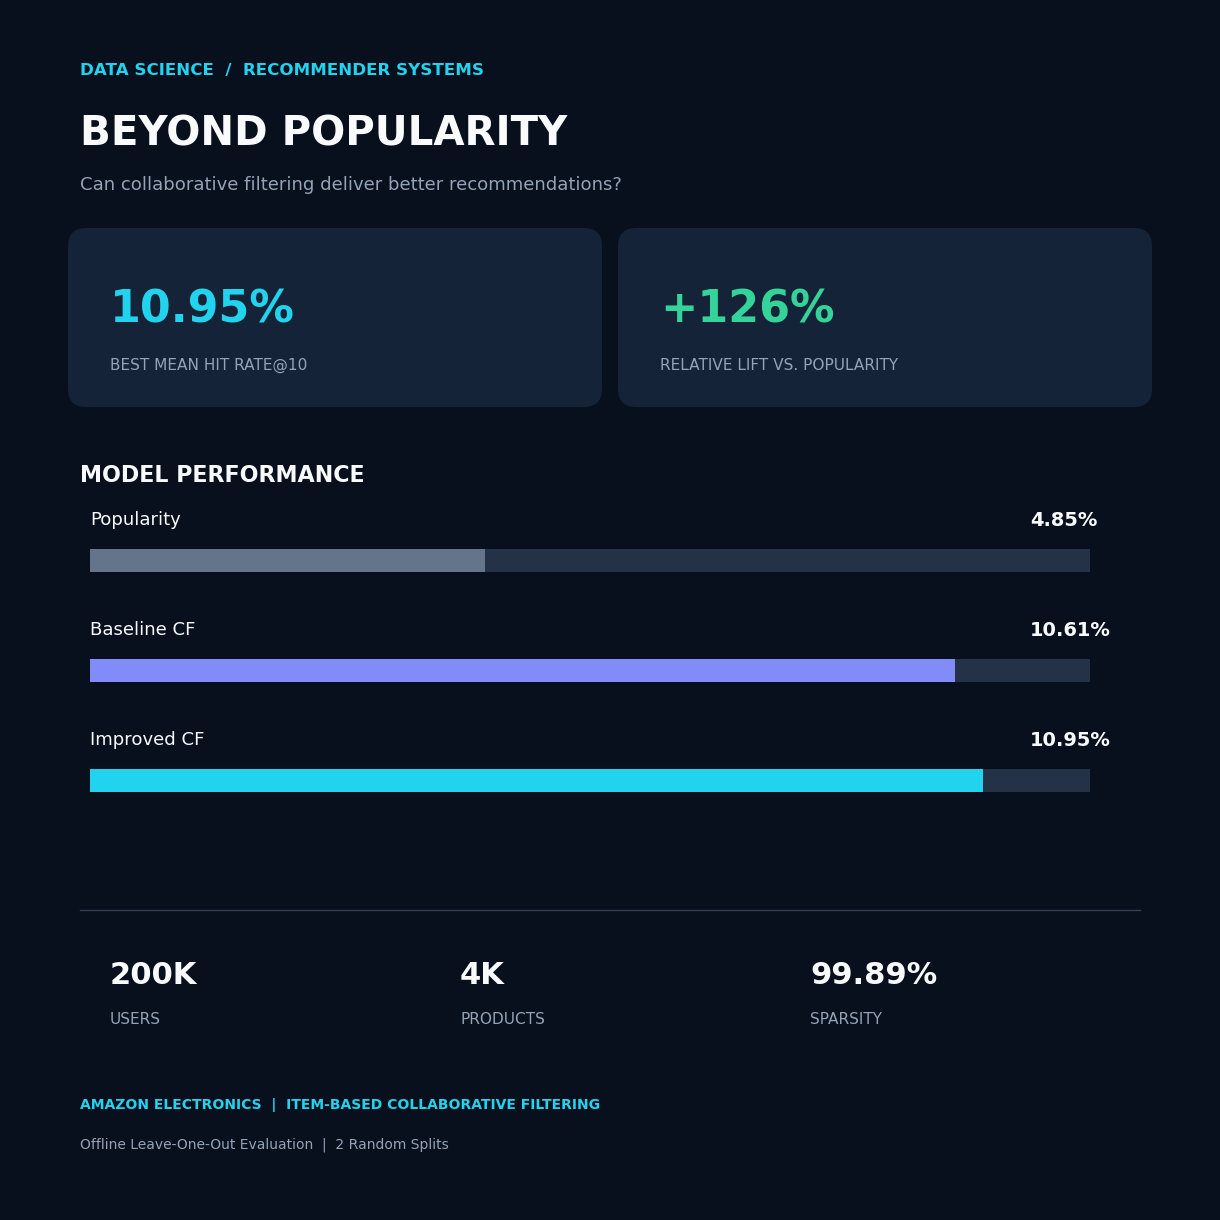

In [34]:
# Real results from notebook
data = robustness.set_index('Model')
models = ['Popularity', 'Baseline CF', 'Improved CF']
values = data.loc[models, 'Mean Hit Rate@10'].to_numpy() * 100

lift = (values[2] / values[0] - 1) * 100

# Colors
bg = '#080F1D'
white = '#F8FAFC'
muted = '#94A3B8'
cyan = '#22D3EE'
green = '#34D399'
colors = ['#64748B', '#818CF8', cyan]

fig = plt.figure(figsize=(12, 12), facecolor=bg)
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, 12)
ax.set_ylim(0, 12)
ax.axis('off')

def txt(x, y, value, size=15, color=white, weight='normal'):
    ax.text(x, y, value, fontsize=size, color=color,
            fontweight=weight, va='center', family='DejaVu Sans')

def panel(x, y, w, h):
    ax.add_patch(FancyBboxPatch(
        (x, y), w, h,
        boxstyle='round,pad=0.12,rounding_size=0.18',
        facecolor='#142338', edgecolor='none'
    ))

# Header
txt(0.7, 11.4, 'DATA SCIENCE  /  RECOMMENDER SYSTEMS',
    12, cyan, 'bold')
txt(0.7, 10.75, 'BEYOND POPULARITY', 29, white, 'bold')
txt(0.7, 10.25, 'Can collaborative filtering deliver better recommendations?',
    13, muted)

# KPI panels
panel(0.7, 8.15, 5.1, 1.55)
panel(6.2, 8.15, 5.1, 1.55)

txt(1.0, 9.0, f'{values[2]:.2f}%', 32, cyan, 'bold')
txt(1.0, 8.45, 'BEST MEAN HIT RATE@10', 11, muted)

txt(6.5, 9.0, f'+{lift:.0f}%', 32, green, 'bold')
txt(6.5, 8.45, 'RELATIVE LIFT VS. POPULARITY', 11, muted)

# Performance bars
txt(0.7, 7.35, 'MODEL PERFORMANCE', 16, white, 'bold')

max_value = max(values) * 1.12

for i, (model, value, color) in enumerate(
    zip(models, values, colors)
):
    y = 6.6 - i * 1.1
    txt(0.8, y + 0.3, model, 13)
    txt(10.2, y + 0.3, f'{value:.2f}%', 14, white, 'bold')

    ax.barh(y - 0.1, 10.0, height=0.23,
            left=0.8, color='#243247')
    ax.barh(y - 0.1, value / max_value * 10.0,
            height=0.23, left=0.8, color=color)

# Dataset information
ax.plot([0.7, 11.3], [3.0, 3.0], color='#334155', lw=1)

for x, value, label in [
    (1.0, '200K', 'USERS'),
    (4.5, '4K', 'PRODUCTS'),
    (8.0, '99.89%', 'SPARSITY')
]:
    txt(x, 2.35, value, 22, white, 'bold')
    txt(x, 1.9, label, 11, muted)

# Footer
txt(0.7, 1.05, 'AMAZON ELECTRONICS  |  ITEM-BASED COLLABORATIVE FILTERING',
    10, cyan, 'bold')
txt(0.7, 0.65, 'Offline Leave-One-Out Evaluation  |  2 Random Splits',
    10, muted)

plt.savefig(
    'amazon_recommendation_linkedin.png',
    dpi=300,
    bbox_inches='tight',
    facecolor=bg
)

plt.show()

In [35]:
joblib.dump(R, "R_sparse.pkl")
joblib.dump(product_ids, "product_ids.pkl")
joblib.dump(prod_to_idx, "prod_to_idx.pkl")

['prod_to_idx.pkl']

## Conclusion

In this project, I built an Amazon Product Recommendation System using Item-Based Collaborative Filtering and Cosine Similarity.

I worked with a dataset of 200,000 users, 4,000 products, and over 858,000 interactions.

The dataset was highly sparse (99.89%), which made finding similar products more challenging. To improve the recommendations, I added a filter requiring at least five shared users between products.

I evaluated three recommendation approaches using Hit Rate@10:

- **Popularity-Based:** 4.85%
- **Baseline Collaborative Filtering:** 10.61%
- **Improved Collaborative Filtering:** 10.95%

The improved model achieved the best results, with approximately **126% higher Hit Rate@10** compared to the popularity-based approach.

These results are based on an offline evaluation with two random data splits.

Through this project, I gained practical experience in data preprocessing, sparse matrices, collaborative filtering, model evaluation, and data visualization.

**Future improvements:** I would like to explore more advanced recommendation algorithms and test the model on different datasets.